## Chủ đề số 14: Bank marketing
## Bài toán: Dự đoán khách hàng có đăng ký gửi tiền kỳ hạn hay không (Yes/No) 
## Loại bài toán: Classification

### Tập dữ liệu: UCI Bank Marketing (https://archive.ics.uci.edu/dataset/222/bank+marketing)
### Sử dụng 4 thuật toán: Logistic Regression, KNN, Decision Tree, RandomForest
### Độ đo: F1, Recall, ROC-AUC

### 1. Giới thiệu bài toán và dữ liệu

#### 1.1. Bài toán

- **Bối cảnh:** dữ liệu ghi lại các cuộc gọi marketing trực tiếp của một ngân hàng nhằm mời khách hàng gửi tiền kỳ hạn.
- **Mục tiêu:** dự đoán khách hàng có đăng ký tiền gửi kỳ hạn hay không, giúp ngân hàng ưu tiên liên hệ nhóm khách tiềm năng và giảm chi phí cuộc gọi.
- **Input:** thông tin khách hàng và chiến dịch marketing (tuổi, nghề nghiệp, lịch sử liên hệ, chỉ số kinh tế vĩ mô...).
- **Output:** `yes` (đăng ký) hoặc `no` (không đăng ký).
- **Loại bài toán:** học có giám sát, phân loại nhị phân (Classification).

#### 1.2. Dữ liệu

Nguồn: UCI Bank Marketing, tệp `bank-additional-full.csv`, gồm 41.188 mẫu và 21 cột (20 thuộc tính và biến mục tiêu `y`).

| Nhóm thuộc tính | Các cột |
|---|---|
| Thông tin khách hàng | `age`, `job`, `marital`, `education`, `default`, `housing`, `loan` |
| Thông tin lần liên hệ hiện tại | `contact`, `month`, `day_of_week`, `duration` |
| Lịch sử chiến dịch | `campaign`, `pdays`, `previous`, `poutcome` |
| Chỉ số kinh tế vĩ mô | `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` |
| Biến mục tiêu | `y` |

Cột `duration` (thời lượng cuộc gọi) chỉ biết sau khi cuộc gọi kết thúc nên sẽ được loại bỏ ở mục 3 để tránh rò rỉ thông tin.

#### 1.3. Đọc dữ liệu

In [1]:
import pandas as pd

df = pd.read_csv("data/bank-additional-full.csv", sep=";")
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### 3. Tiền xử lý dữ liệu

Các bước thực hiện (theo đúng thứ tự):

1. Loại bản ghi trùng và bản ghi thiếu nhãn.
2. Giữ `unknown` như một nhóm riêng của biến phân loại.
3. Loại cột `duration` để tránh rò rỉ thông tin.
4. Tách đặc trưng `X` và nhãn `y` (`no` thành 0, `yes` thành 1).
5. Chia train/test theo tỷ lệ 80/20 với `stratify=y` và `random_state=42`. Việc chia được thực hiện **trước** khi chuẩn hóa để tránh rò rỉ thông tin từ tập test.
6. Biến số: điền giá trị thiếu bằng trung vị rồi chuẩn hóa `StandardScaler`. Biến phân loại: điền giá trị thiếu bằng giá trị phổ biến nhất rồi mã hóa One-Hot.
7. Các bộ xử lý chỉ `fit` trên tập train, sau đó `transform` cho tập test.

In [ ]:
import sys

sys.path.append("..")  # Để notebook nhìn thấy thư mục src/ ở ngoài
from src.preprocessing import load_and_preprocess_data

X_train, X_test, y_train, y_test, preprocessor = load_and_preprocess_data()
feature_names = preprocessor.get_feature_names_out()

Số dòng sau khi loại trùng/thiếu nhãn: 41176
Số đặc trưng sau mã hóa: 62
Train: X=(32940, 62), y=(32940,)
Test:  X=(8236, 62), y=(8236,)
Tỷ lệ nhãn trong train (%):
y
no     88.73
yes    11.27
Name: proportion, dtype: float64


### 6. Thuật toán Decision Tree

#### 6.1. Giới thiệu thuật toán

Decision Tree là thuật toán học có giám sát chia dữ liệu liên tiếp theo các điều kiện trên đặc trưng (ví dụ `euribor3m < 1,3`) để tạo thành cây quyết định. Mỗi nút lá cho một dự đoán yes hoặc no.

- **Ưu điểm:** dễ hiểu, trực quan, không cần chuẩn hóa dữ liệu, cho biết đặc trưng nào quan trọng.
- **Nhược điểm:** dễ overfitting nếu cây quá sâu, kết quả không ổn định khi dữ liệu thay đổi nhẹ.

Cấu hình baseline: `max_depth=8`, `min_samples_split=20`, `min_samples_leaf=10` để giới hạn độ phức tạp của cây, `class_weight="balanced"` để xử lý mất cân bằng lớp, `random_state=42`.

#### 6.2. Huấn luyện và dự đoán

Huấn luyện mô hình trên tập train, sau đó dự đoán nhãn và xác suất đăng ký (lớp "yes") trên tập test.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Khởi tạo mô hình Decision Tree baseline
model_dt = DecisionTreeClassifier(
    max_depth=8,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

# Huấn luyện trên tập train
model_dt.fit(X_train, y_train)

# Dự đoán nhãn và xác suất đăng ký (lớp "yes") trên tập test
yes_index = list(model_dt.classes_).index(1)
y_pred_dt = model_dt.predict(X_test)
y_proba_dt = model_dt.predict_proba(X_test)[:, yes_index]

print("Huấn luyện và dự đoán Decision Tree hoàn tất!")
print("\n10 nhãn dự đoán đầu tiên:", y_pred_dt[:10])
print("10 xác suất dự đoán đầu tiên:", y_proba_dt[:10].round(4))

Huấn luyện và dự đoán Decision Tree hoàn tất!

10 nhãn dự đoán đầu tiên: [0 1 1 1 0 0 1 0 0 0]
10 xác suất dự đoán đầu tiên: [0.3164 0.9717 0.525  0.525  0.3421 0.2306 0.525  0.2433 0.3421 0.3421]


In [ ]:
from src.evaluation import evaluate_model

metrics = evaluate_model(
    model_name="Decision Tree (Baseline)",
    y_true=y_test,
    y_pred=y_pred_dt,
    y_prob=y_proba_dt,
)

#### 6.3. Đánh giá mô hình

Đánh giá trên tập test bằng F1-score, Recall, ROC-AUC (độ đo thầy gợi ý), bổ sung Accuracy và Precision. Do dữ liệu mất cân bằng nên F1-score và Recall được ưu tiên hơn Accuracy.#### Dự đoán kết quả

In [4]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Tính các chỉ số
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt, zero_division=0)
recall_dt = recall_score(y_test, y_pred_dt, zero_division=0)
f1_dt = f1_score(y_test, y_pred_dt, zero_division=0)
auc_dt = roc_auc_score(y_test, y_proba_dt)

# Hiển thị kết quả
print("===== DECISION TREE BASELINE =====")
print(f"Accuracy : {accuracy_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall   : {recall_dt:.4f}")
print(f"F1-score : {f1_dt:.4f}")
print(f"ROC-AUC  : {auc_dt:.4f}")

# Báo cáo chi tiết theo từng lớp
print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test,
    y_pred_dt,
    labels=[0, 1],
    target_names=["No", "Yes"],
    zero_division=0
))

===== DECISION TREE BASELINE =====
Accuracy : 0.8263
Precision: 0.3530
Recall   : 0.6509
F1-score : 0.4577
ROC-AUC  : 0.7932

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.95      0.85      0.90      7308
         Yes       0.35      0.65      0.46       928

    accuracy                           0.83      8236
   macro avg       0.65      0.75      0.68      8236
weighted avg       0.88      0.83      0.85      8236



#### 6.4. Trực quan hóa kết quả

Confusion Matrix cho biết số khách hàng mô hình đoán đúng và sai ở từng lớp, đặc biệt là số khách hàng thật sự đăng ký nhưng bị bỏ sót (False Negative). ROC Curve cho biết khả năng phân biệt hai lớp ở mọi ngưỡng phân loại.#### Đánh giá mô hình

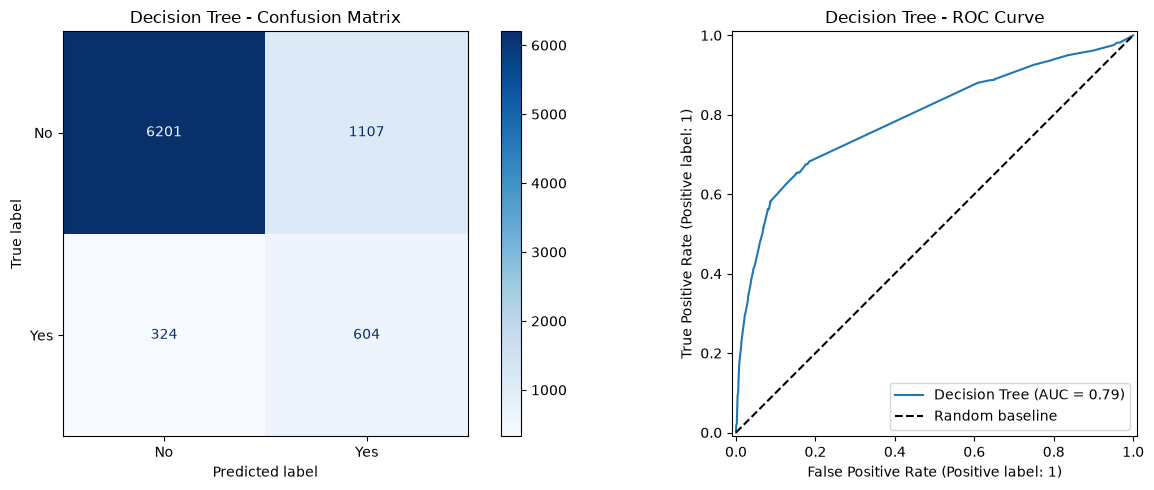

In [5]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt,
    display_labels=["No", "Yes"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Decision Tree - Confusion Matrix")

# Biểu đồ ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_dt,
    name="Decision Tree",
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
axes[1].set_title("Decision Tree - ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

#### 6.5. Nhận xét và lưu kết quả

**Nhận xét (theo lần chạy với `random_state=42`, cập nhật lại nếu chạy ra số khác):**

- Decision Tree đạt F1-score ≈ 0,46, Recall ≈ 0,65 và ROC-AUC ≈ 0,79 trên tập test, gần tương đương Logistic Regression (F1 ≈ 0,46, Recall ≈ 0,65, ROC-AUC ≈ 0,80) và cao hơn hẳn KNN, Random Forest về Recall.
- Recall cao nhờ `class_weight="balanced"`, đổi lại Precision chỉ khoảng 0,35: khoảng 65% khách hàng được dự đoán là "yes" thực tế không đăng ký. Accuracy ≈ 0,83 thấp hơn mức 88,7% của mô hình đoán toàn bộ là "no", nhưng mô hình đó vô dụng vì Recall bằng 0.
- Việc giới hạn độ sâu (`max_depth=8`) và kích thước nút lá giúp cây tránh overfitting; đây là lý do kết quả tốt hơn nhiều so với cây không giới hạn.
- Hướng cải thiện: tinh chỉnh `max_depth`, `min_samples_leaf` bằng GridSearchCV, và so sánh với Random Forest (xem mục 10). Độ quan trọng của đặc trưng được phân tích ở mục 12.

Kết quả được lưu vào danh sách chung `all_results` để so sánh với các mô hình khác ở mục 8.

In [6]:
# Danh sách kết quả chung của cả nhóm (tạo mới nếu chưa có)
if "all_results" not in globals():
    all_results = []
if "all_probas" not in globals():
    all_probas = {}

all_results.append({
    "Model": "Decision Tree (baseline)",
    "Accuracy": accuracy_dt,
    "Precision": precision_dt,
    "Recall": recall_dt,
    "F1-score": f1_dt,
    "ROC-AUC": auc_dt
})
all_probas["Decision Tree (baseline)"] = y_proba_dt

print("Đã lưu kết quả Decision Tree!")

Đã lưu kết quả Decision Tree!


### 9. Xử lý mất cân bằng lớp và chỉnh ngưỡng


#### 9.3. Decision Tree

Thực hiện cân bằng dữ liệu trên tập train bằng SMOTE. Sử dụng cùng bộ dữ liệu, cách chia train/test và cấu trúc Decision Tree như baseline. Thay phương pháp xử lý mất cân bằng bằng SMOTE, huấn luyện mô hình trên tập train sau khi cân bằng và đánh giá trên tập test ban đầu.

In [10]:
#%pip install imblearn

In [11]:
from imblearn.over_sampling import SMOTE
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

In [13]:
# Cân bằng dữ liệu trên tập train
smote_dt = SMOTE(random_state=42)

X_train_smote_dt, y_train_smote_dt = smote_dt.fit_resample(X_train, y_train)

print("Phân bố lớp trước SMOTE:")
print(y_train.value_counts())
print("\nPhân bố lớp sau SMOTE:")
print(y_train_smote_dt.value_counts())

Phân bố lớp trước SMOTE:
y
0    29229
1     3711
Name: count, dtype: int64

Phân bố lớp sau SMOTE:
y
0    29229
1    29229
Name: count, dtype: int64


In [15]:
# Khởi tạo Decision Tree
model_dt_smote = DecisionTreeClassifier(
    max_depth=8,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight=None,
    random_state=42
)

# Huấn luyện trên dữ liệu đã cân bằng
model_dt_smote.fit(X_train_smote_dt, y_train_smote_dt)

# Dự đoán trên tập test gốc
y_pred_dt_smote = model_dt_smote.predict(X_test)
y_proba_dt_smote = model_dt_smote.predict_proba(X_test)[:, 1]

In [17]:
# Tính các độ đo
metrics_dt_smote = {
    "Accuracy": accuracy_score(y_test, y_pred_dt_smote),
    "Precision": precision_score(y_test, y_pred_dt_smote, zero_division=0),
    "Recall": recall_score(y_test, y_pred_dt_smote, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_dt_smote, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_proba_dt_smote)
}

print("\n===== DECISION TREE + SMOTE (EXP-07) =====")

for k, v in metrics_dt_smote.items():
    print(f"{k:<10}: {v:.4f}")

print("\n===== CLASSIFICATION REPORT =====")

print(classification_report(
    y_test,
    y_pred_dt_smote,
    labels=[0, 1],
    target_names=["No", "Yes"],
    zero_division=0
))


===== DECISION TREE + SMOTE (EXP-07) =====
Accuracy  : 0.8696
Precision : 0.4391
Recall    : 0.5668
F1-score  : 0.4948
ROC-AUC   : 0.7891

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.94      0.91      0.93      7308
         Yes       0.44      0.57      0.49       928

    accuracy                           0.87      8236
   macro avg       0.69      0.74      0.71      8236
weighted avg       0.89      0.87      0.88      8236



In [ ]:
from src.evaluation import evaluate_model

metrics = evaluate_model(
    model_name="Decision Tree (SMOTE)",
    y_true=y_test,
    y_pred=y_pred_dt_smote,
    y_prob=y_proba_dt_smote,
)

So sánh chênh lệch

In [18]:
baseline_dt = {
    "Accuracy": accuracy_dt,
    "Precision": precision_dt,
    "Recall": recall_dt,
    "F1-score": f1_dt,
    "ROC-AUC": auc_dt
}

comparison_dt = pd.DataFrame({
    "Baseline": baseline_dt,
    "EXP-07 (SMOTE)": metrics_dt_smote
})

comparison_dt["Chênh lệch"] = (
    comparison_dt["EXP-07 (SMOTE)"]
    - comparison_dt["Baseline"]
)

display(comparison_dt.round(4))

,Baseline,EXP-07 (SMOTE),Chênh lệch
Accuracy,0.8263,0.8696,0.0433
Precision,0.3530,0.4391,0.0861
Recall,0.6509,0.5668,-0.0841
F1-score,0.4577,0.4948,0.0371
ROC-AUC,0.7932,0.7891,-0.0040


##### Nhận xét: 

Sau khi áp dụng SMOTE, mô hình Decision Tree có Accuracy tăng từ 0,8263 lên 0,8696 (+0,0433), Precision tăng từ 0,3530 lên 0,4391 (+0,0861) và F1-score tăng từ 0,4577 lên 0,4948 (+0,0371). Ngược lại, Recall giảm từ 0,6509 xuống 0,5668 (-0,0841), ROC-AUC giảm nhẹ từ 0,7932 xuống 0,7891 (-0,0041). Kết quả cho thấy SMOTE giúp cải thiện Precision và F1-score, giảm các trường hợp dự đoán nhầm khách hàng đăng ký, nhưng đồng thời làm giảm khả năng nhận diện khách hàng thực sự đăng ký. Nhìn chung, mô hình đạt F1-score tốt hơn baseline, tuy nhiên mức cải thiện chưa lớn và vẫn tồn tại sự đánh đổi giữa Precision và Recall.